In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ml import load_aapl, build_features, split_chronologique, train_random_forest, evaluate

df = load_aapl("../data/aapl.csv")
print(df.shape, df.columns.tolist())
df.head()

(1254, 5) ['Open', 'High', 'Low', 'Close', 'Volume']


,Open,High,Low,Close,Volume
Date,,,,,
2021-11-22 00:00:00-05:00,157.808261,161.731999,157.144553,157.164078,117467900
2021-11-23 00:00:00-05:00,157.261705,157.925429,155.251038,157.544769,96041900
2021-11-24 00:00:00-05:00,156.900537,158.257250,155.817117,158.062042,69463600
2021-11-26 00:00:00-05:00,155.748755,156.607672,152.615619,153.054840,76959800
2021-11-29 00:00:00-05:00,155.553564,157.329988,154.987452,156.402740,88748200


In [2]:
feat = build_features(df["Close"], df["Volume"])
print(feat.shape)
feat.head()

(1233, 7)


,ret,volume,ret_lag1,vol_5,vol_10,vol_20,target
Date,,,,,,,
2021-12-21 00:00:00-05:00,0.018907,91185900,-0.008155,0.423678,0.360098,0.340194,0.015203
2021-12-22 00:00:00-05:00,0.015203,92135300,0.018907,0.373727,0.349590,0.342631,0.003637
2021-12-23 00:00:00-05:00,0.003637,68356600,0.015203,0.195143,0.349422,0.342620,0.022715
2021-12-27 00:00:00-05:00,0.022715,74919600,0.003637,0.200344,0.339664,0.319858,0.005784
2021-12-28 00:00:00-05:00,-0.005784,79144300,0.022715,0.186706,0.320992,0.318005,0.000502


In [3]:
X_tr, X_te, y_tr, y_te = split_chronologique(feat, test_ratio=0.2)
print(f"Train: {X_tr.shape}, Test: {X_te.shape}")
print(f"Train index: {X_tr.index.min()} → {X_tr.index.max()}")
print(f"Test  index: {X_te.index.min()} → {X_te.index.max()}")
assert X_tr.index.max() < X_te.index.min(), "Fuite temporelle !"

Train: (986, 6), Test: (247, 6)
Train index: 2021-12-21 00:00:00-05:00 → 2025-11-24 00:00:00-05:00
Test  index: 2025-11-25 00:00:00-05:00 → 2026-11-18 00:00:00-05:00


In [4]:
rf = train_random_forest(X_tr, y_tr)
rmse_rf, rmse_naive = evaluate(rf, X_te, y_te)
print(f"RMSE RF       : {rmse_rf:.6f}")
print(f"RMSE baseline : {rmse_naive:.6f}")
print(f"Le RF bat la baseline : {rmse_rf < rmse_naive}")

RMSE RF       : 0.011533
RMSE baseline : 0.241266
Le RF bat la baseline : True


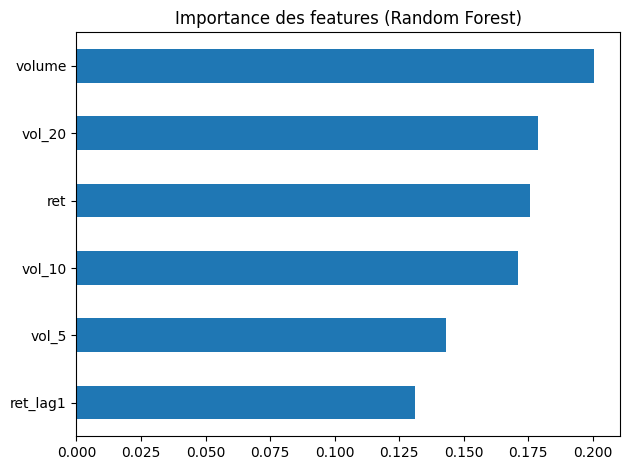

In [5]:
importances = pd.Series(rf.feature_importances_, index=X_tr.columns).sort_values()
importances.plot(kind="barh", title="Importance des features (Random Forest)")
plt.tight_layout()
plt.savefig("../docs/figures/rf_importances.png", dpi=110)
plt.show()